# Task 9 – Event/Background Classification and Voice Activity Detection on VOiCES
Digital Speech Processing

**Instructor:** Dr. Mohammad Khalooei  
**Student:** Abbas Almijbilee (عباس المجبلي)  
**Student ID:** 404131082

Steps:
1. Download the VOiCES subset and look at the metadata
2. Listen to and plot one utterance under the four background conditions
3. Background (distractor) classification with five classifiers
4. Voice activity detection: energy VAD, Silero VAD and trained frame classifiers
5. Background classification using only the pauses found by the VAD

## Step 1 – Download the VOiCES subset

In [ ]:
!git clone --depth 1 https://github.com/Lab41/VOiCES-subset.git

import glob, os, tarfile
import pandas as pd
import soundfile as sf

os.makedirs("voices", exist_ok=True)
for t in sorted(glob.glob("VOiCES-subset/VOiCES_90_*.tar")):
    with tarfile.open(t) as tf:
        for m in tf.getmembers():
            if m.name.endswith(".wav"):
                m.name = os.path.basename(m.name)   # drop the long folder path
                tf.extract(m, "voices", filter="data")

files = sorted(glob.glob("voices/*.wav"))
print("WAV files:", len(files))

# file name: Lab41-SRI-VOiCES-<room>-<distractor>-sp<speaker>-ch<chapter>-sg<segment>-mc<mic>-<type>-<location>-dg<degree>
rows = []
for f in files:
    p = os.path.basename(f)[:-4].split("-")
    info = sf.info(f)
    rows.append({"file": f, "room": p[3], "distractor": p[4], "speaker": p[5],
                 "utterance": "-".join(p[5:8]), "mic": p[8], "mic_location": p[10],
                 "sr": info.samplerate, "duration": info.duration})
meta = pd.DataFrame(rows)

print("\nSample rates:", meta["sr"].unique())
print("Duration (s): min %.2f | mean %.2f | max %.2f | total %.2f h" % (
    meta.duration.min(), meta.duration.mean(), meta.duration.max(), meta.duration.sum() / 3600))
print("Speakers:", meta.speaker.nunique(), "| Utterances:", meta.utterance.nunique())
print("\nRecordings per distractor:\n", meta.distractor.value_counts().to_string())
print("\nRecordings per room:\n", meta.room.value_counts().to_string())
print("\nRecordings per microphone:\n", meta.groupby(["mic", "mic_location"]).size().to_string())

Cloning into 'VOiCES-subset'...
remote: Enumerating objects: 25, done.
remote: Counting objects: 100% (25/25), done.
remote: Compressing objects: 100% (24/24), done.
remote: Total 25 (delta 1), reused 24 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (25/25), 365.22 MiB | 18.66 MiB/s, done.
Resolving deltas: 100% (1/1), done.
Updating files: 100% (22/22), done.
WAV files: 908

Sample rates: [16000]
Duration (s): min 2.66 | mean 15.56 | max 19.10 | total 3.92 h
Speakers: 104 | Utterances: 128

Recordings per distractor:
 distractor
musi    231
babb    228
none    227
tele    222

Recordings per room:
 room
rm2    462
rm1    446

Recordings per microphone:
 mic   mic_location
mc01  clo             251
mc03  mid             211
mc05  far             219
mc07  beh             227


## Step 2 – One utterance under the four background conditions

Chosen utterance: sp0083-ch003054-sg0005 | room: rm2
             mic mic_location
distractor                   
none        mc03          mid
babb        mc03          mid
musi        mc01          clo
tele        mc01          clo


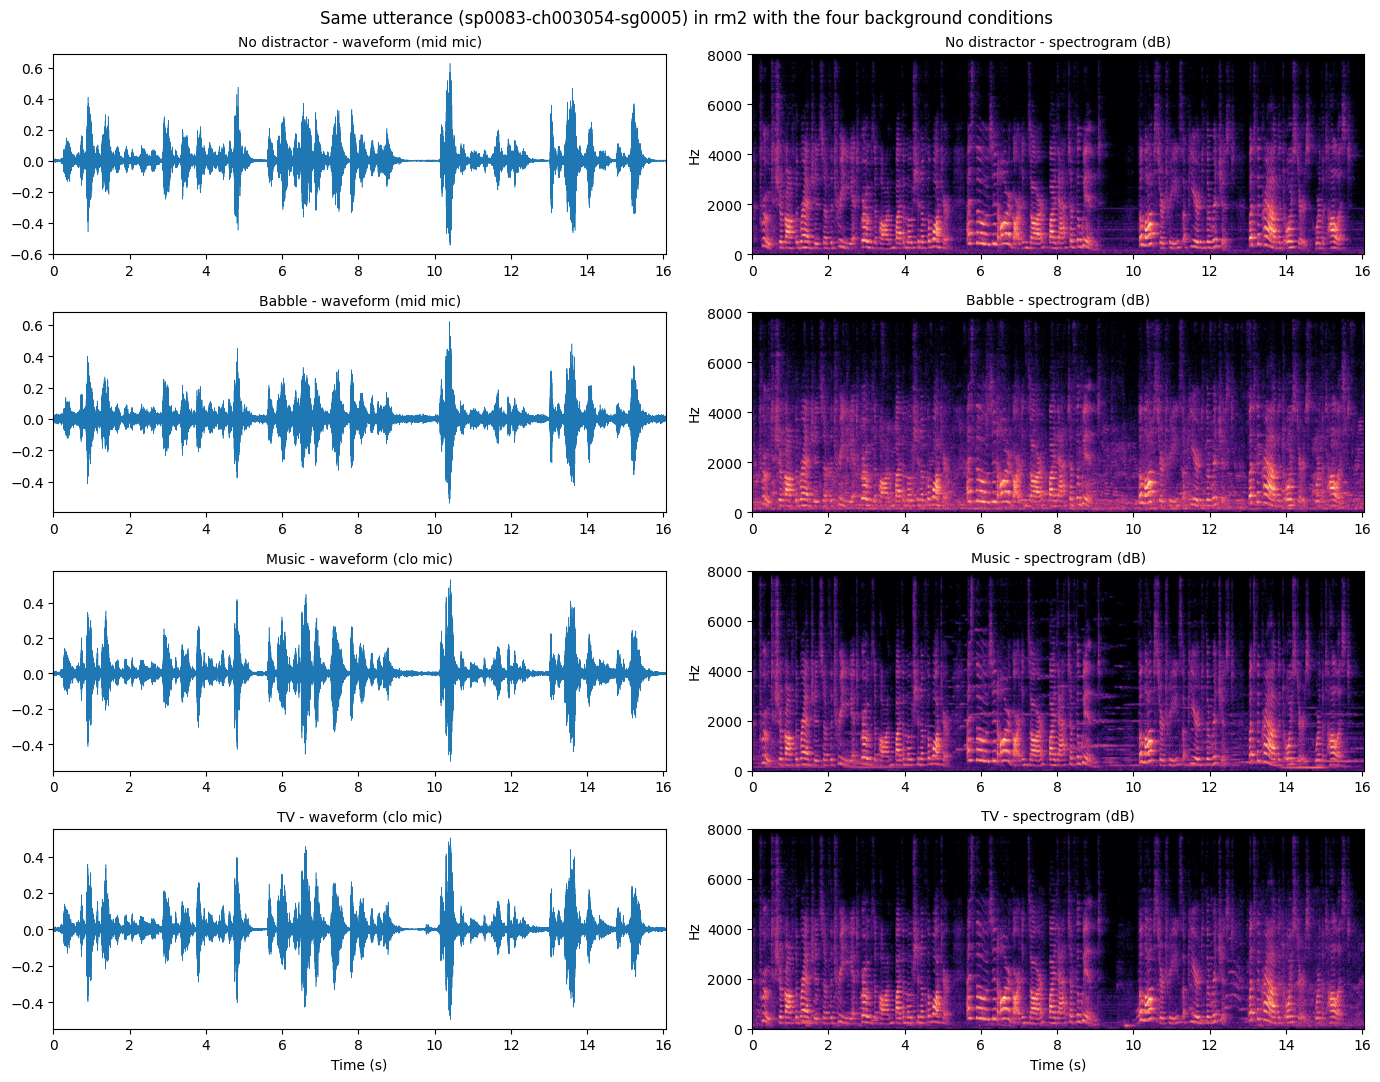

No distractor


Babble


Music


TV


In [ ]:
import numpy as np, torch, torchaudio, matplotlib.pyplot as plt
from IPython.display import Audio, display
os.makedirs("figures", exist_ok=True)

order = ["none", "babb", "musi", "tele"]
names = {"none": "No distractor", "babb": "Babble", "musi": "Music", "tele": "TV"}

# pick one utterance recorded with all four distractors in the same room,
# using the closest available microphone for each distractor
best = None
for (utt, room), g in meta.groupby(["utterance", "room"]):
    if not set(order) <= set(g.distractor):
        continue
    pick = g.sort_values("mic").groupby("distractor").head(1).set_index("distractor")
    score = sum(int(m[2:]) for m in pick.mic)
    if best is None or score < best[0]:
        best = (score, utt, room, pick)
_, utt, room, ex = best
print("Chosen utterance:", utt, "| room:", room)
print(ex[["mic", "mic_location"]].loc[order].to_string())

spec_tf = torchaudio.transforms.Spectrogram(n_fft=512, hop_length=160)
to_db = torchaudio.transforms.AmplitudeToDB(top_db=80)
fig, axes = plt.subplots(4, 2, figsize=(14, 11))
for row, d in enumerate(order):
    x, sr = sf.read(ex.loc[d, "file"], dtype="float32")
    t = np.arange(len(x)) / sr
    axes[row, 0].plot(t, x, linewidth=0.4)
    axes[row, 0].set_title(f"{names[d]} - waveform ({ex.loc[d, 'mic_location']} mic)", fontsize=10)
    axes[row, 0].set_xlim(0, t[-1])
    S = to_db(spec_tf(torch.tensor(x)))
    axes[row, 1].imshow(S, origin="lower", aspect="auto", cmap="magma",
                        extent=[0, t[-1], 0, sr / 2])
    axes[row, 1].set_title(f"{names[d]} - spectrogram (dB)", fontsize=10)
    axes[row, 1].set_ylabel("Hz")
for ax in axes[-1]:
    ax.set_xlabel("Time (s)")
plt.suptitle(f"Same utterance ({utt}) in {room} with the four background conditions")
plt.tight_layout()
plt.savefig("figures/distractor_examples.png", dpi=150)
plt.show()

# listen to the four versions
for d in order:
    x, sr = sf.read(ex.loc[d, "file"], dtype="float32")
    print(names[d])
    display(Audio(x, rate=sr))

## Step 3 – Background (distractor) classification

Feature matrix: (908, 60)  (17 s)
Train: 666 files / 78 speakers | Test: 242 files / 26 speakers | shared speakers: 0
                      Test accuracy  Test macro-F1  CV accuracy (mean)  CV accuracy (std)
Model                                                                                    
SVM (RBF)                    0.7479         0.7453              0.7742             0.0338
Neural Network (MLP)         0.7438         0.7418              0.7257             0.0404
Random Forest                0.7397         0.7349              0.6927             0.0366
k-NN (k=5)                   0.6364         0.6354              0.5727             0.0177
Logistic Regression          0.6860         0.6889              0.6905             0.0407


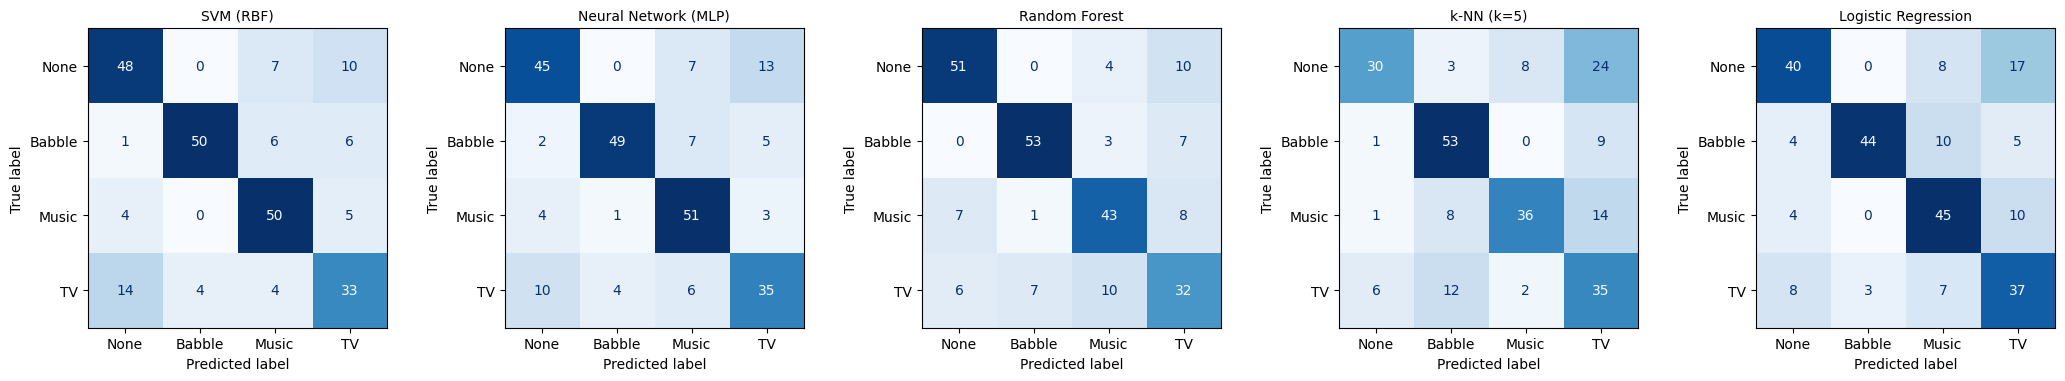


Test accuracy of SVM (RBF) per microphone position:
mic
clo    0.773
mid    0.714
far    0.750
beh    0.754


In [ ]:
# ---- Step 3: background (distractor) classification ----
import time, warnings
warnings.filterwarnings("ignore")
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

mfcc_tf = torchaudio.transforms.MFCC(
    sample_rate=16000, n_mfcc=20,
    melkwargs={"n_fft": 512, "hop_length": 160, "n_mels": 40})

def file_features(x):
    m = mfcc_tf(torch.tensor(x))                      # (20, frames)
    d = torchaudio.functional.compute_deltas(m)
    return torch.cat([m.mean(1), m.std(1), d.std(1)]).numpy()   # 60 values

t0 = time.time()
X = np.stack([file_features(sf.read(f, dtype="float32")[0]) for f in meta.file])
y = meta.distractor.values
groups = meta.speaker.values
print(f"Feature matrix: {X.shape}  ({time.time() - t0:.0f} s)")

# hold out 25% of the speakers as a test set
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
tr, te = next(gss.split(X, y, groups))
print("Train:", len(tr), "files /", len(set(groups[tr])), "speakers | Test:",
      len(te), "files /", len(set(groups[te])), "speakers | shared speakers:",
      len(set(groups[tr]) & set(groups[te])))

models = {
    "SVM (RBF)": SVC(kernel="rbf", C=1.0, gamma="scale"),
    "Neural Network (MLP)": MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=2000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
    "k-NN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Logistic Regression": LogisticRegression(max_iter=3000),
}
results, preds = [], {}
for name, model in models.items():
    pipe = make_pipeline(StandardScaler(), model)
    pipe.fit(X[tr], y[tr])
    p = pipe.predict(X[te]); preds[name] = p
    cv = cross_val_score(make_pipeline(StandardScaler(), model), X, y,
                         groups=groups, cv=GroupKFold(n_splits=5))
    results.append({"Model": name,
                    "Test accuracy": accuracy_score(y[te], p),
                    "Test macro-F1": f1_score(y[te], p, average="macro"),
                    "CV accuracy (mean)": cv.mean(), "CV accuracy (std)": cv.std()})
bg_df = pd.DataFrame(results).set_index("Model").round(4)
print(bg_df.to_string())

labels = ["none", "babb", "musi", "tele"]
fig, axes = plt.subplots(1, len(models), figsize=(4.2 * len(models), 3.8))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y[te], p, labels=labels),
                           display_labels=["None", "Babble", "Music", "TV"]).plot(
        ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.savefig("figures/background_confusion_matrices.png", dpi=150)
plt.show()

# accuracy of the best model for each microphone position
best_name = bg_df["CV accuracy (mean)"].idxmax()
per_mic = (pd.DataFrame({"mic": meta.mic_location.values[te], "ok": preds[best_name] == y[te]})
           .groupby("mic").ok.mean().reindex(["clo", "mid", "far", "beh"]).round(3))
print(f"\nTest accuracy of {best_name} per microphone position:\n{per_mic.to_string()}")

## Step 4 – Voice activity detection
The close microphone (mc01) gives the reference labels; the methods are tested on the distant microphone recorded at the same time.

Close/distant pairs: 108 | speakers: 64
mic_location  beh
distractor       
babb           26
musi           27
none           28
tele           27
Reference labels built (68 s). Speech frames in reference: 86.3%
Train pairs: 78 | Test pairs: 30 | shared speakers: 0
Energy VAD: best margin above noise floor on training pairs = 1 dB

VAD results on test pairs (distant mics). 'Always speech' accuracy = 0.8579
                      Accuracy  Precision  Recall      F1
Energy VAD              0.9175     0.9423  0.9627  0.9524
Silero VAD              0.9842     0.9907  0.9909  0.9908
Logistic Regression     0.9504     0.9655  0.9771  0.9713
Random Forest           0.9571     0.9648  0.9859  0.9753
Neural Network (MLP)    0.9601     0.9705  0.9834  0.9769

F1 per distractor (test pairs):
                       none   babb   musi   tele
Energy VAD            0.976  0.947  0.941  0.954
Silero VAD            0.995  0.992  0.986  0.992
Logistic Regression   0.976  0.969  0.972  0.970
Random Fores

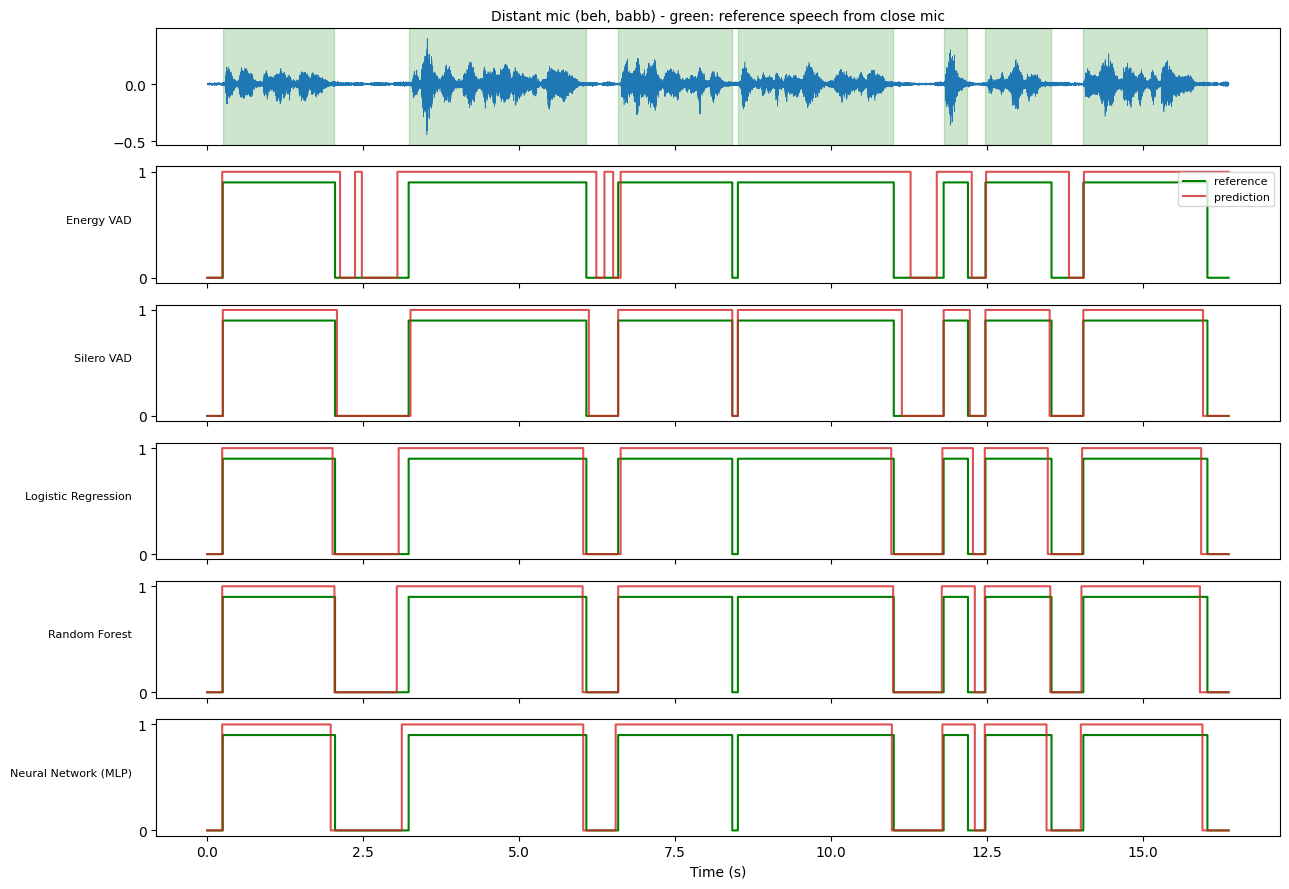

In [6]:
# ---- Step 4: Voice Activity Detection ----
!pip install -q silero-vad

from silero_vad import load_silero_vad, get_speech_timestamps
from scipy.ndimage import median_filter
from sklearn.metrics import precision_score, recall_score

HOP = 160                                   # 10 ms frames at 16 kHz
silero = load_silero_vad()

def silero_frames(x):
    """Silero VAD -> one 0/1 label per 10 ms frame."""
    ts = get_speech_timestamps(torch.tensor(x), silero, sampling_rate=16000)
    lab = np.zeros(1 + len(x) // HOP, dtype=int)
    for t in ts:
        lab[t["start"] // HOP: t["end"] // HOP + 1] = 1
    return lab

power_tf = torchaudio.transforms.Spectrogram(n_fft=512, hop_length=HOP, power=2.0)
def log_energy(x):
    return 10 * np.log10(power_tf(torch.tensor(x)).sum(0).numpy() + 1e-10)

def frame_features(x):
    m = mfcc_tf(torch.tensor(x))
    d = torchaudio.functional.compute_deltas(m)
    e = torch.tensor(log_energy(x))[None]
    return torch.cat([m, d, e - e.max()]).T.numpy()          # (frames, 41)

# pairs: same room + distractor + utterance, recorded at the same time by the
# close mic (mc01) and by a distant mic -> the close mic gives the reference
pairs = []
for (room, dist, utt), g in meta.groupby(["room", "distractor", "utterance"]):
    if "mc01" in set(g.mic) and len(g) > 1:
        ref = g[g.mic == "mc01"].iloc[0]
        for _, row in g[g.mic != "mc01"].iterrows():
            pairs.append({"ref_file": ref.file, "file": row.file, "distractor": dist,
                          "speaker": row.speaker, "mic_location": row.mic_location})
pairs = pd.DataFrame(pairs)
print("Close/distant pairs:", len(pairs), "| speakers:", pairs.speaker.nunique())
print(pairs.groupby(["distractor", "mic_location"]).size().unstack(fill_value=0).to_string())

t0 = time.time()
data = []
for _, p in pairs.iterrows():
    xr = sf.read(p.ref_file, dtype="float32")[0]
    xd = sf.read(p.file, dtype="float32")[0]
    n = min(len(xr), len(xd))
    ref = silero_frames(xr[:n])
    feats = frame_features(xd[:n])
    k = min(len(ref), len(feats))
    data.append({"ref": ref[:k], "feats": feats[:k], "x": xd[:n],
                 "silero": silero_frames(xd[:n])[:k]})
print(f"Reference labels built ({time.time() - t0:.0f} s). "
      f"Speech frames in reference: {np.mean(np.concatenate([d['ref'] for d in data])):.1%}")

# split the pairs by speaker
gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
ptr, pte = next(gss.split(pairs, groups=pairs.speaker))
print("Train pairs:", len(ptr), "| Test pairs:", len(pte),
      "| shared speakers:", len(set(pairs.speaker[ptr]) & set(pairs.speaker[pte])))

# 1) energy VAD: frame is speech if it is more than k dB above the noise floor
#    (10th percentile of the frame energies); k is tuned on the training pairs
def energy_vad(feats, k):
    e = feats[:, -1]
    return median_filter((e > np.percentile(e, 10) + k).astype(int), size=11)

ks = np.arange(0, 21, 1)
train_f1 = [f1_score(np.concatenate([data[i]["ref"] for i in ptr]),
                     np.concatenate([energy_vad(data[i]["feats"], k) for i in ptr])) for k in ks]
best_k = ks[int(np.argmax(train_f1))]
print("Energy VAD: best margin above noise floor on training pairs =", best_k, "dB")

# 2) Silero VAD on the distant mic was already computed above (data[i]['silero'])

# 3) trained frame classifiers on MFCC + delta + energy, with 5 frames of context
def with_context(f, c=5):
    pad = np.pad(f, ((c, c), (0, 0)), mode="edge")
    return np.hstack([pad[i:i + len(f)] for i in range(0, 2 * c + 1, 5)])

Xf_tr = np.vstack([with_context(data[i]["feats"]) for i in ptr])
yf_tr = np.concatenate([data[i]["ref"] for i in ptr])
rng = np.random.default_rng(0)
sub = rng.choice(len(yf_tr), size=min(60000, len(yf_tr)), replace=False)   # keep training fast
frame_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42),
    "Neural Network (MLP)": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, random_state=42),
}
for name, mdl in frame_models.items():
    frame_models[name] = make_pipeline(StandardScaler(), mdl).fit(Xf_tr[sub], yf_tr[sub])

# evaluate all methods on the test pairs (distant microphones)
def evaluate(pred_fn):
    yt = np.concatenate([data[i]["ref"] for i in pte])
    yp = np.concatenate([pred_fn(i) for i in pte])
    return {"Accuracy": accuracy_score(yt, yp), "Precision": precision_score(yt, yp),
            "Recall": recall_score(yt, yp), "F1": f1_score(yt, yp)}

methods = {
    "Energy VAD": lambda i: energy_vad(data[i]["feats"], best_k),
    "Silero VAD": lambda i: data[i]["silero"],
}
for name, mdl in frame_models.items():
    methods[name] = (lambda m: lambda i: median_filter(
        m.predict(with_context(data[i]["feats"])), size=11))(mdl)

preds_vad = {name: {i: fn(i) for i in pte} for name, fn in methods.items()}
vad_df = pd.DataFrame({name: evaluate(lambda i, n=name: preds_vad[n][i])
                       for name in methods}).T.round(4)
always = np.mean(np.concatenate([data[i]["ref"] for i in pte]))
print(f"\nVAD results on test pairs (distant mics). 'Always speech' accuracy = {always:.4f}")
print(vad_df.to_string())

# F1 per distractor type
per_dist = {}
for name in methods:
    per_dist[name] = {}
    for d in ["none", "babb", "musi", "tele"]:
        idx = [i for i in pte if pairs.distractor[i] == d]
        if idx:
            yt = np.concatenate([data[i]["ref"] for i in idx])
            yp = np.concatenate([preds_vad[name][i] for i in idx])
            per_dist[name][d] = f1_score(yt, yp)
print("\nF1 per distractor (test pairs):")
print(pd.DataFrame(per_dist).T.round(3).to_string())

# example plot: one test pair
i = pte[0]
x = data[i]["x"]; tt = np.arange(len(data[i]["ref"])) * HOP / 16000
fig, ax = plt.subplots(len(methods) + 1, 1, figsize=(13, 9), sharex=True)
ax[0].plot(np.arange(len(x)) / 16000, x, linewidth=0.4)
ax[0].fill_between(tt, 0, 1, where=data[i]["ref"] == 1, color="green", alpha=0.2,
                   transform=ax[0].get_xaxis_transform())
ax[0].set_title(f"Distant mic ({pairs.mic_location[i]}, {pairs.distractor[i]}) - green: reference speech from close mic",
                fontsize=10)
for a, name in zip(ax[1:], methods):
    a.step(tt, data[i]["ref"] * 0.9, color="green", where="post", label="reference")
    a.step(tt, preds_vad[name][i], color="tab:red", where="post", alpha=0.8, label="prediction")
    a.set_yticks([0, 1]); a.set_ylabel(name, fontsize=8, rotation=0, ha="right")
ax[1].legend(loc="upper right", fontsize=8)
ax[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.savefig("figures/vad_example.png", dpi=150)
plt.show()

## Step 5 – Background classification using only the pauses

Done in 294 s. Pause (non-speech) share per file: mean 13.6%, min 1.5%

Background classification, 5-fold CV accuracy (grouped by speaker):
                      Whole file (Step 3)  Speech frames only  Pause frames only  Whole file + pauses
SVM (RBF)                          0.7742              0.6574             0.9064               0.9075
Neural Network (MLP)               0.7257              0.6309             0.9052               0.9086
Random Forest                      0.6927              0.5891             0.8843               0.8877
k-NN (k=5)                         0.5727              0.5099             0.8403               0.8183
Logistic Regression                0.6905              0.6067             0.9020               0.8921


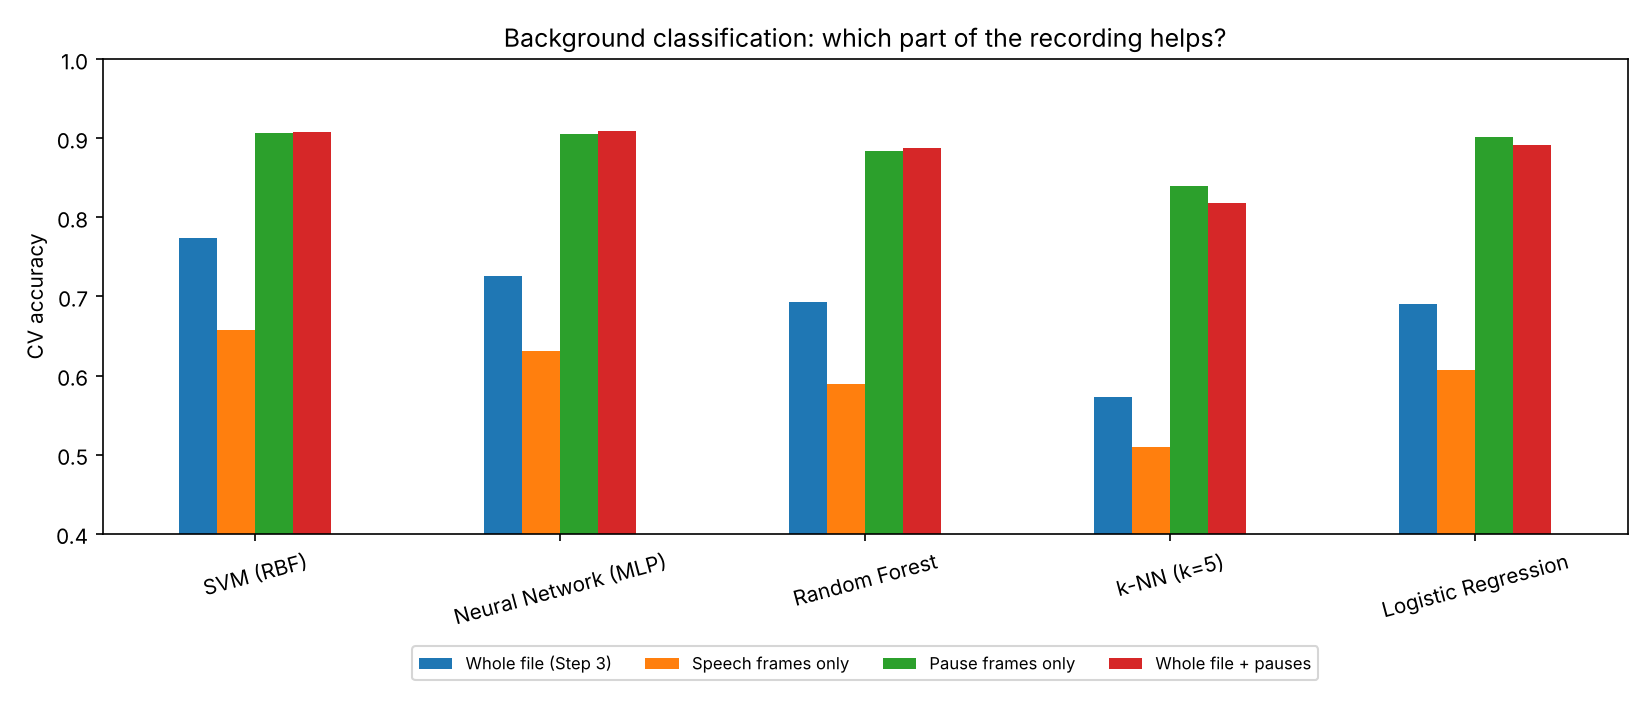

In [7]:
# ---- Step 5: background classification using the pauses only ----
t0 = time.time()
X_pause, X_speech, pause_frac = [], [], []
for f in meta.file:
    x = sf.read(f, dtype="float32")[0]
    m = mfcc_tf(torch.tensor(x))                                  # (20, frames)
    d = torchaudio.functional.compute_deltas(m)
    lab = silero_frames(x)[:m.shape[1]]
    lab = np.pad(lab, (0, m.shape[1] - len(lab)), constant_values=1)
    nonsp = lab == 0
    if nonsp.sum() < 10:              # almost no pause -> fall back to the whole file
        nonsp = np.ones_like(nonsp, dtype=bool)
    pm, pd_ = m[:, nonsp], d[:, nonsp]
    sm, sd = m[:, lab == 1], d[:, lab == 1]
    X_pause.append(torch.cat([pm.mean(1), pm.std(1), pd_.std(1)]).numpy())
    X_speech.append(torch.cat([sm.mean(1), sm.std(1), sd.std(1)]).numpy())
    pause_frac.append(1 - lab.mean())
X_pause, X_speech = np.stack(X_pause), np.stack(X_speech)
print(f"Done in {time.time() - t0:.0f} s. Pause (non-speech) share per file: "
      f"mean {np.mean(pause_frac):.1%}, min {np.min(pause_frac):.1%}")

feature_sets = {
    "Whole file (Step 3)": X,
    "Speech frames only": X_speech,
    "Pause frames only": X_pause,
    "Whole file + pauses": np.hstack([X, X_pause]),
}
rows = {}
for fs_name, F in feature_sets.items():
    rows[fs_name] = {}
    for name, model in models.items():
        cv = cross_val_score(make_pipeline(StandardScaler(), model), F, y,
                             groups=groups, cv=GroupKFold(n_splits=5))
        rows[fs_name][name] = cv.mean()
pause_df = pd.DataFrame(rows).round(4)
print("\nBackground classification, 5-fold CV accuracy (grouped by speaker):")
print(pause_df.to_string())

ax = pause_df.plot(kind="bar", figsize=(11, 4.8), rot=15)
ax.set_ylim(0.4, 1.0); ax.set_ylabel("CV accuracy")
ax.set_title("Background classification: which part of the recording helps?")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=4)
plt.tight_layout()
plt.savefig("figures/background_pause_features.png", dpi=150)
plt.show()